# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

Вызовы библиотек сверены с актуальной документацией. Все численные выводы ниже опираются на выполненные ячейки.

In [1]:
%pip install -q -r wine_app/requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from scipy.special import expit
from sklearn.base import clone
from sklearn.utils import ClassifierTags
from IPython.display import display

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def __sklearn_tags__(self):
        # Сохраняем порядок базовых классов шаблона и явно задаем тип модели.
        tags = super().__sklearn_tags__()
        tags.estimator_type = 'classifier'
        tags.classifier_tags = ClassifierTags()
        tags.target_tags.required = True
        return tags

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.shape != (len(X),) or len(X) == 0:
            raise ValueError('Нужны непустая матрица X и вектор y той же длины')
        if not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError('В данных есть пропуски или бесконечности')
        if not np.array_equal(np.unique(y), [0, 1]):
            raise ValueError('В y должны присутствовать оба класса: 0 и 1')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError("gd_type должен быть 'full' или 'stochastic'")
        if self.eta <= 0 or self.max_iter < 1 or self.tolerance < 0 or self.batch_size < 1:
            raise ValueError('Некорректные параметры градиентного спуска')
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        X_bias = np.column_stack([np.ones(len(X)), X])
        self.w = (np.zeros(X_bias.shape[1]) if self.w0 is None
                  else np.asarray(self.w0, dtype=float).copy())
        if self.w.shape != (X_bias.shape[1],) or not np.isfinite(self.w).all():
            raise ValueError('w0 должен содержать d + 1 конечных чисел')
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)
        self.stop_reason_ = 'max_iter'
        for iteration in range(self.max_iter):
            # История начинается с loss до первого обновления весов.
            self.loss_history.append(self.calc_loss(X_bias, y))
            if self.gd_type == 'full':
                gradient = self.calc_gradient(X_bias, y)
            else:
                idx = rng.choice(len(y), size=min(self.batch_size, len(y)), replace=False)
                gradient = self.calc_gradient(X_bias[idx], y[idx])
            step = self.eta * gradient
            self.w -= step
            self.n_iter_ = iteration + 1
            self.last_weight_change_ = np.linalg.norm(step)
            if self.last_weight_change_ < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break
        self.final_loss_ = self.calc_loss(X_bias, y)
        return self

    def sigmoid(self, z):
        return expit(z)

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise ValueError('Модель еще не обучена')
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] + 1 != len(self.w):
            raise ValueError('Число признаков не совпадает с обучением')
        X_bias = np.column_stack([np.ones(len(X)), X])
        p = self.sigmoid(X_bias @ self.w)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        if not 0 <= threshold <= 1:
            raise ValueError('Порог должен лежать в [0, 1]')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        return X.T @ (self.sigmoid(X @ self.w) - y) / len(y)

    def calc_loss(self, X, y):
        z = X @ self.w
        # log(1 + exp(z)) - y*z, без переполнения и log(0).
        return float(np.mean(np.logaddexp(0, z) - y * z))


Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 3.27e-11


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,Метод,Итерации,Остановка,Изменение весов,Финальный loss,Объектов для градиента,Объектов для loss
0,GD,1000,max_iter,0.000399,0.512435,14000,14000
1,SGD,1000,max_iter,0.003895,0.512909,32,14000


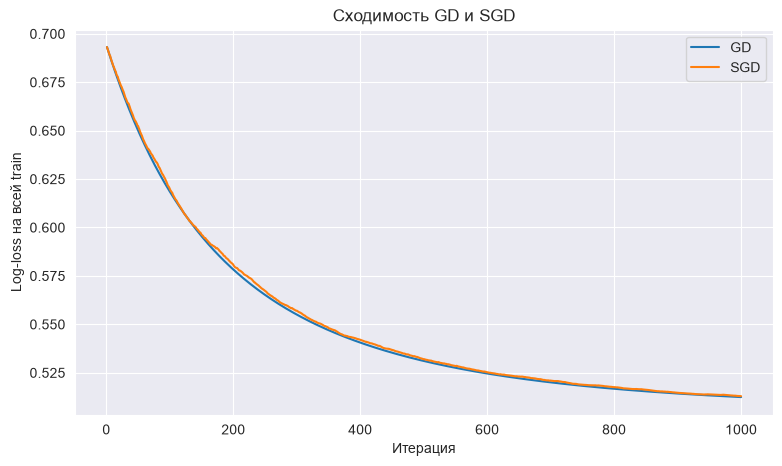

In [6]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
display(pd.DataFrame([
    {'Метод': name, 'Итерации': model.n_iter_, 'Остановка': model.stop_reason_,
     'Изменение весов': model.last_weight_change_, 'Финальный loss': model.final_loss_,
     'Объектов для градиента': len(y_train) if name == 'GD' else model.batch_size,
     'Объектов для loss': len(y_train)}
    for name, model in [('GD', gd), ('SGD', sgd)]]))
plt.figure(figsize=(9, 5))
for name, model in [('GD', gd), ('SGD', sgd)]:
    plt.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history, label=name)
plt.xlabel('Итерация')
plt.ylabel('Log-loss на всей train')
plt.title('Сходимость GD и SGD')
plt.legend()
plt.show()

Обе модели сделали 1000 итераций и остановились по max_iter. Последнее изменение весов у GD примерно 0.000399, а у SGD 0.003895: оба значения больше tolerance=0.0001.

У GD loss убывает плавно, у SGD на общем нисходящем тренде есть небольшие колебания. Градиент случайного батча шумит даже рядом с минимумом, поэтому с постоянным шагом разность соседних весов не обязана стать маленькой. Случайное выполнение tolerance тоже не доказывало бы сходимость полной функции.

Для градиента GD просматривает 14000 объектов за шаг, SGD — 32. Но по условию loss оба считают на всех 14000 объектах на каждой итерации. Поэтому в этой реализации вычисление истории съедает часть выигрыша SGD по времени.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

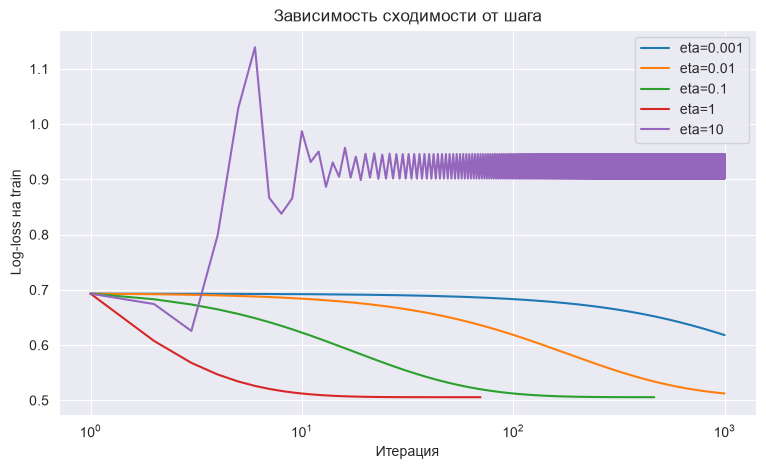

,eta,Итерации,Финальный loss,Остановка
0,0.001,1000,0.618087,max_iter
1,0.010,1000,0.512435,max_iter
2,0.100,465,0.505762,tolerance
3,1.000,70,0.505757,tolerance
4,10.000,1000,0.901345,max_iter


In [7]:
eta_models = {}
plt.figure(figsize=(9, 5))
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(eta=eta).fit(X_train, y_train)
    eta_models[eta] = model
    plt.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history, label=f'eta={eta}')
plt.xscale('log')
plt.xlabel('Итерация')
plt.ylabel('Log-loss на train')
plt.title('Зависимость сходимости от шага')
plt.legend()
plt.show()
pd.DataFrame([{'eta': eta, 'Итерации': model.n_iter_,
               'Финальный loss': model.final_loss_, 'Остановка': model.stop_reason_}
              for eta, model in eta_models.items()])

При eta=0.001 и 0.01 за 1000 шагов спуск еще не успел сойтись: loss примерно 0.6181 и 0.5124. При eta=0.1 понадобилось 465 шагов, при eta=1 — 70; оба запуска остановились по tolerance с loss около 0.50576.

При eta=10 шаг уже слишком большой: loss колеблется и в конце около 0.9013, хуже остальных запусков. Это не уход в бесконечность, но устойчивого приближения к минимуму нет. Увеличение шага помогает только до тех пор, пока обновления не начинают перескакивать через область минимума.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sklearn_lr = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)
synthetic_metrics = pd.DataFrame([
    {'Модель': name, 'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
     'ROC-AUC': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])}
    for name, model in [('Свой GD', gd), ('Свой SGD', sgd), ('sklearn', sklearn_lr)]])
display(synthetic_metrics)
display(pd.DataFrame({'Свой GD': gd.w,
                      'sklearn': np.r_[sklearn_lr.intercept_, sklearn_lr.coef_.ravel()]},
                     index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])]))
# Дополнительно сравним решения одной задачи при более строгой сходимости.
gd_converged = LogReg(eta=1, max_iter=20000, tolerance=1e-9).fit(X_train, y_train)
lr_unregularized = LogisticRegression(C=np.inf, tol=1e-10, max_iter=2000,
                                     random_state=RANDOM_STATE).fit(X_train, y_train)
display(pd.Series({
    'GD loss после сходимости': gd_converged.final_loss_,
    'sklearn без регуляризации loss': metrics.log_loss(y_train, lr_unregularized.predict_proba(X_train)),
    'Максимальная разница весов без регуляризации': np.max(np.abs(
        gd_converged.w - np.r_[lr_unregularized.intercept_, lr_unregularized.coef_.ravel()]))}))

,Модель,accuracy,ROC-AUC
0,Свой GD,0.7820,0.838787
1,Свой SGD,0.7825,0.838115
2,sklearn,0.7765,0.838676


,Свой GD,sklearn
intercept,-0.002114,-0.021880
x0,0.006076,0.002741
x1,0.006963,0.009039
x2,-0.547170,-0.722690
x3,-0.144536,-0.262335
x4,0.012487,0.016588
x5,-0.006325,-0.011488
x6,0.000814,0.005587
x7,0.039084,0.057188
x8,-0.002425,-0.001239


GD loss после сходимости                        5.057566e-01
sklearn без регуляризации loss                  5.057566e-01
Максимальная разница весов без регуляризации    8.808672e-09
dtype: float64

Метрики близки, но не одинаковы: accuracy своего GD и SGD около 0.782, у sklearn 0.7765; ROC-AUC у всех около 0.838. По таблице весов различия заметнее. Дефолтный GD еще не сошелся, а у sklearn вдобавок по умолчанию есть L2-регуляризация с C=1.

Для сравнения без регуляризации задаю в sklearn `C=np.inf`. После более точной сходимости своего GD loss обеих моделей около 0.5057566, максимальная разница весов примерно $8.8\cdot10^{-9}$.

В этих синтетических данных есть линейно зависимые признаки, поэтому в общем случае совпадение оптимального loss не гарантирует единственности весов. Здесь оба метода пришли практически к одному вектору.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
from pathlib import Path

data_path = Path('Data/wine_quality.csv')
if not data_path.exists():
    data_path = Path('homework/hw_3/Data/wine_quality.csv')
df_raw = pd.read_csv(data_path)
print('Исходный размер:', df_raw.shape)
print('Пропуски:', df_raw.isna().sum().sum())
print('Полные дубликаты:', df_raw.duplicated().sum())
df = df_raw.drop_duplicates().reset_index(drop=True)
print('После удаления дубликатов:', df.shape)
df.head()

Исходный размер: (6497, 13)
Пропуски: 0
Полные дубликаты: 1177
После удаления дубликатов: (5320, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,1,0


Полные дубликаты удаляю **до разбиения**, чтобы одинаковая строка не оказалась и в train, и в test. Идентификаторов образцов нет, поэтому считаю полностью одинаковые строки повторами наблюдений. Дальше все модели сравниваются на одном разбиении очищенных данных.

In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (3724, 12)  Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
display(df.isna().sum())
print('Дубликаты после очистки:', df.duplicated().sum())
print('Доля класса 1 на train:', y_train.mean())
print('Доля класса 1 на test:', y_test.mean())
print('Размеры классов train:')
display(y_train.value_counts().sort_index())
constant_pred = np.zeros(len(y_test), dtype=int)
baseline = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_proba = baseline.predict_proba(X_test)[:, 1]
display(pd.Series({'accuracy константы': metrics.accuracy_score(y_test, constant_pred),
                   'accuracy логрегрессии': metrics.accuracy_score(y_test, baseline_pred)}))

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
is_red                  0
target                  0
dtype: int64

Дубликаты после очистки: 0
Доля класса 1 на train: 0.1895810955961332
Доля класса 1 на test: 0.18984962406015038
Размеры классов train:


target
0    3018
1     706
Name: count, dtype: int64

accuracy константы       0.810150
accuracy логрегрессии    0.815163
dtype: float64

Пропусков нет, а в исходной таблице было 1177 полных повторов. Я удалил их до train/test split; осталось 5320 строк. Иначе одинаковые наблюдения могли бы попасть в обе выборки и сделать проверку менее честной.

Доля хороших вин на train примерно 18.96%, на test 18.98%. stratify сохраняет пропорции классов в обеих частях с учетом округления числа объектов.

Константа получила accuracy около 0.8102, логрегрессия — 0.8152. Разница маленькая, хотя константа вообще не отбирает хорошие вина. Accuracy в основном определяется многочисленным классом 0 и не показывает, сколько хороших вин мы пропустили и насколько надежна подборка.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP, TN, FP, FN: 92 1209 84 211


array([[1209,   84],
       [ 211,   92]])

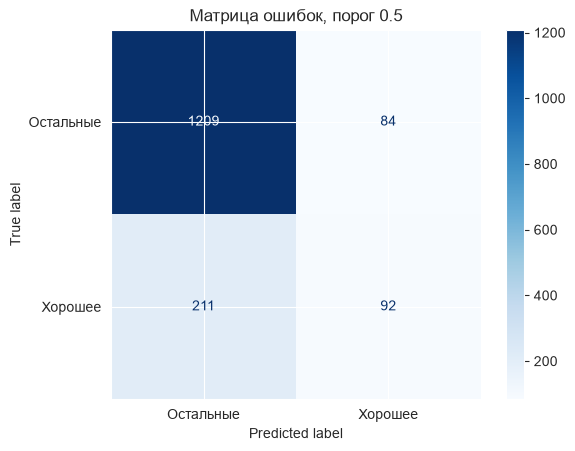

In [12]:
actual = y_test.to_numpy()
TP = np.sum((actual == 1) & (baseline_pred == 1))
TN = np.sum((actual == 0) & (baseline_pred == 0))
FP = np.sum((actual == 0) & (baseline_pred == 1))
FN = np.sum((actual == 1) & (baseline_pred == 0))
manual_cm = np.array([[TN, FP], [FN, TP]])
print('TP, TN, FP, FN:', TP, TN, FP, FN)
display(manual_cm)
assert np.array_equal(manual_cm, metrics.confusion_matrix(y_test, baseline_pred))
metrics.ConfusionMatrixDisplay(manual_cm, display_labels=['Остальные', 'Хорошее']).plot(cmap='Blues')
plt.title('Матрица ошибок, порог 0.5')
plt.show()

FP — посредственное вино, которое модель рекомендует как хорошее: в подборку попадает неудачная рекомендация. FN — хорошее вино, которое модель не включила в подборку.

При пороге 0.5 получилось FP=84 и FN=211. Чаще модель пропускает хорошие вина, чем ошибочно рекомендует посредственные. Матрица, посчитанная вручную, совпала со sklearn.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
manual_f = {beta: (1 + beta**2) * precision * recall / (beta**2 * precision + recall)
            for beta in [0.5, 1, 2]}
manual_values = [precision, recall, manual_f[1], manual_f[0.5], manual_f[2]]
sklearn_values = [metrics.precision_score(y_test, baseline_pred, zero_division=0),
                  metrics.recall_score(y_test, baseline_pred, zero_division=0),
                  metrics.f1_score(y_test, baseline_pred, zero_division=0),
                  metrics.fbeta_score(y_test, baseline_pred, beta=0.5, zero_division=0),
                  metrics.fbeta_score(y_test, baseline_pred, beta=2, zero_division=0)]
assert np.allclose(manual_values, sklearn_values)
pd.DataFrame({'Вручную': manual_values, 'sklearn': sklearn_values},
             index=['precision', 'recall', 'F1', 'F0.5', 'F2'])

,Вручную,sklearn
precision,0.522727,0.522727
recall,0.303630,0.303630
F1,0.384134,0.384134
F0.5,0.456802,0.456802
F2,0.331412,0.331412


$F_{0.5}$ сильнее учитывает precision, а $F_2$ — recall. В первом случае важнее, чтобы отобранные вина действительно были хорошими; во втором — чтобы меньше хороших вин осталось за бортом.

Если подписчики болезненно реагируют на посредственные вина, я бы выбрал $F_{0.5}$. Если обещаем максимально широкую подборку — $F_2$. Обычная $F_1$ симметрично учитывает precision и recall, но сама по себе не задает цену ошибок в деньгах.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

,eta,validation log-loss,Итерации,Остановка
0,0.1,0.374202,20000,max_iter
1,1.0,0.374261,5162,tolerance


Итоговый свой GD: 4876 tolerance


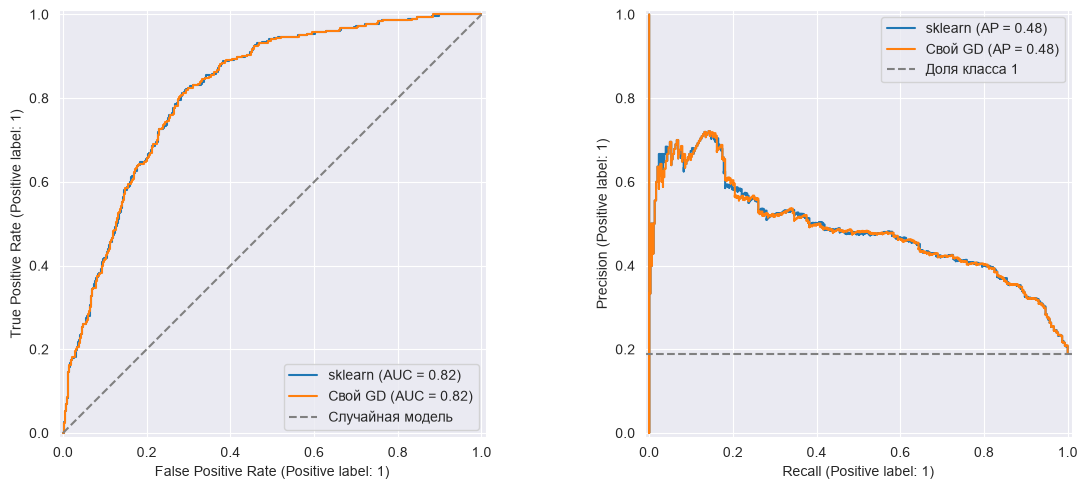

,Модель,ROC-AUC,PR-AUC (AP)
0,sklearn,0.820876,0.484766
1,Свой GD,0.820562,0.483769


p            0.820876
10*p         0.820876
p**3         0.820876
logit(p)     0.820876
-p           0.179124
Метки 0/1    0.619333
Name: ROC-AUC, dtype: float64

Доля класса 1 / случайный PR-AUC: 0.18984962406015038
Balanced accuracy: 0.6193325829102632


In [14]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
# Шаг своей модели выбираем по log-loss на валидации, test не используем.
custom_candidates = []
for eta in [0.1, 1.0]:
    candidate = make_pipeline(StandardScaler(), LogReg(eta=eta, max_iter=20000, tolerance=1e-7))
    candidate.fit(X_fit, y_fit)
    custom_candidates.append({'eta': eta,
        'validation log-loss': metrics.log_loss(y_val, candidate.predict_proba(X_val)),
        'Итерации': candidate[-1].n_iter_, 'Остановка': candidate[-1].stop_reason_})
display(pd.DataFrame(custom_candidates))
converged_candidates = [row for row in custom_candidates if row['Остановка'] == 'tolerance']
best_eta = min(converged_candidates, key=lambda row: row['validation log-loss'])['eta']
custom_wine = make_pipeline(StandardScaler(), LogReg(eta=best_eta, max_iter=20000, tolerance=1e-7))
custom_wine.fit(X_train, y_train)
print('Итоговый свой GD:', custom_wine[-1].n_iter_, custom_wine[-1].stop_reason_)
wine_scores = {'sklearn': baseline_proba, 'Свой GD': custom_wine.predict_proba(X_test)[:, 1]}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, score in wine_scores.items():
    metrics.RocCurveDisplay.from_predictions(y_test, score, name=name, ax=axes[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, score, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Случайная модель')
axes[0].legend()
axes[1].axhline(y_test.mean(), ls='--', color='gray', label='Доля класса 1')
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame([{'Модель': name, 'ROC-AUC': metrics.roc_auc_score(y_test, score),
                       'PR-AUC (AP)': metrics.average_precision_score(y_test, score)}
                      for name, score in wine_scores.items()]))
p = baseline_proba
p_clipped = np.clip(p, np.finfo(float).eps, 1 - np.finfo(float).eps)
display(pd.Series({name: metrics.roc_auc_score(y_test, score) for name, score in {
    'p': p, '10*p': 10*p, 'p**3': p**3, 'logit(p)': np.log(p_clipped / (1-p_clipped)),
    '-p': -p, 'Метки 0/1': baseline_pred}.items()}, name='ROC-AUC'))
print('Доля класса 1 / случайный PR-AUC:', y_test.mean())
print('Balanced accuracy:', metrics.balanced_accuracy_score(y_test, baseline_pred))

По обеим метрикам немного лучше sklearn: ROC-AUC около 0.82088 против 0.82056, AP около 0.48477 против 0.48377. Ранжирование моделей по двум метрикам совпало, но считать такую маленькую разницу убедительным преимуществом без оценки неопределенности я бы не стал. Свой GD обучен без регуляризации, а у sklearn она есть. Для своей модели выбран eta=1 среди сошедшихся запусков по validation log-loss; на всей train критерий tolerance выполнился за 4876 итераций.

Уровень случайного ранжирования на PR-графике равен доле положительного класса, здесь примерно 0.18985. Поэтому он не равен 0.5: хороших вин меньше половины. Для конечной случайной перестановки конкретный AP может немного отличаться от этого базового уровня. Здесь под PR-AUC использую average precision, как требует задание, а не трапецеидальную площадь.

Умножение p на 10, куб и logit строго возрастают и сохраняют порядок объектов, поэтому ROC-AUC остается около 0.820876. Оценки для AUC не обязаны быть вероятностями. При -p порядок переворачивается, получается $1-AUC\approx0.179124$.

Если передать метки 0/1, ROC-AUC посчитается, но почти вся информация о ранжировании потеряется: останется одна рабочая точка и концы ROC-кривой. Здесь получится около 0.61933, что совпадает с balanced accuracy при этом пороге.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

,Порог,precision,recall,F1
641,0.236359,0.426117,0.704545,0.531049
696,0.286550,0.470339,0.630682,0.538835


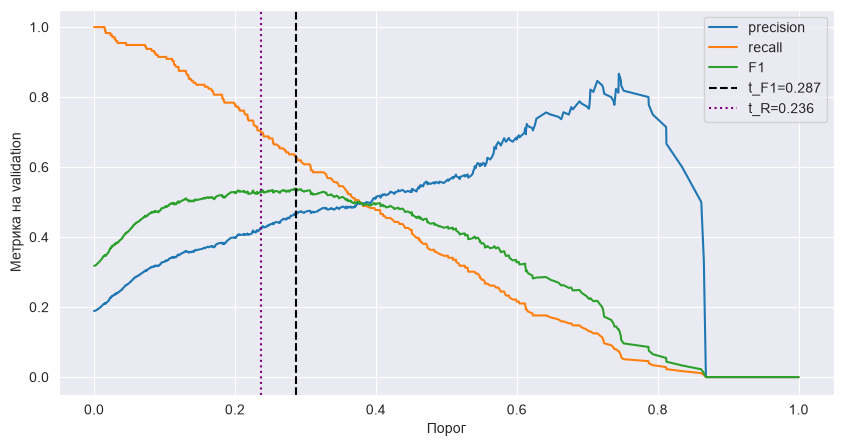

,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,"Без весов, 0.5",0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
1,"Без весов, t_F1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
2,"Без весов, t_R",0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


In [15]:
validation_model = clone(baseline).fit(X_fit, y_fit)
val_proba = validation_model.predict_proba(X_val)[:, 1]
# Все различные решения на валидации: уникальные вероятности и концы [0, 1].
thresholds = np.unique(np.r_[0, val_proba, 1])
threshold_table = pd.DataFrame([
    {'Порог': t, 'precision': metrics.precision_score(y_val, val_proba >= t, zero_division=0),
     'recall': metrics.recall_score(y_val, val_proba >= t, zero_division=0),
     'F1': metrics.f1_score(y_val, val_proba >= t, zero_division=0)} for t in thresholds])
t_F1 = float(threshold_table.loc[threshold_table['F1'].idxmax(), 'Порог'])
eligible = threshold_table[threshold_table['recall'] >= 0.7]
best_recall_row = eligible.sort_values(['precision', 'F1', 'Порог'], ascending=False).iloc[0]
t_R = float(best_recall_row['Порог'])
display(threshold_table[threshold_table['Порог'].isin([t_F1, t_R])])
threshold_table.plot(x='Порог', y=['precision', 'recall', 'F1'], figsize=(10, 5))
plt.axvline(t_F1, ls='--', label=f't_F1={t_F1:.3f}', color='black')
plt.axvline(t_R, ls=':', label=f't_R={t_R:.3f}', color='purple')
plt.ylabel('Метрика на validation')
plt.legend()
plt.show()
baseline.fit(X_train, y_train)
baseline_proba = baseline.predict_proba(X_test)[:, 1]

def score_row(name, model=None, threshold=0.5, proba=None, truth=None):
    truth = y_test if truth is None else truth
    proba = model.predict_proba(X_test)[:, 1] if proba is None else np.asarray(proba)
    pred = proba >= threshold
    return {'Модель': name, 'Порог': threshold, 'accuracy': metrics.accuracy_score(truth, pred),
            'precision': metrics.precision_score(truth, pred, zero_division=0),
            'recall': metrics.recall_score(truth, pred, zero_division=0),
            'F1': metrics.f1_score(truth, pred, zero_division=0),
            'ROC-AUC': metrics.roc_auc_score(truth, proba),
            'PR-AUC': metrics.average_precision_score(truth, proba)}

threshold_results = pd.DataFrame([
    score_row(name, proba=baseline_proba, threshold=t)
    for name, t in [('Без весов, 0.5', 0.5), ('Без весов, t_F1', t_F1), ('Без весов, t_R', t_R)]])
display(threshold_results)

По валидации получились $t_{F_1}\approx0.28655$ и $t_R\approx0.23636$. При втором пороге validation recall около 0.7045, precision около 0.4261.

На test при t_R условие recall >= 0.7 тоже выполнилось: recall около 0.7063, precision около 0.4213, F1 около 0.5277. При t_F1 recall около 0.6205, зато precision выше — около 0.4574. При 0.5 recall всего около 0.3036.

Гарантии переноса ограничения нет: validation и test — разные конечные выборки, а после переобучения изменились и вероятности модели. При сдвиге распределения расхождение может быть еще сильнее. Я бы использовал t_R, если сервис действительно требует отбирать не меньше 70% хороших вин. Если важнее избегать посредственных рекомендаций, нужен другой компромисс, например подбор по F0.5, а не обещание 70% recall.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
balanced = make_pipeline(StandardScaler(), LogisticRegression(
    class_weight='balanced', random_state=RANDOM_STATE)).fit(X_train, y_train)
class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (2 * class_counts)
display(pd.DataFrame({'Число объектов': class_counts, 'Вес': class_weights}))
model_results = [score_row('Без весов', model=baseline), score_row('Веса balanced', model=balanced)]
pd.DataFrame(model_results)

,Число объектов,Вес
target,,
0,3018,0.616965
1,706,2.637394


,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,Без весов,0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
1,Веса balanced,0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147


Веса классов считаются по формуле $w_k=n/(K n_k)$. Здесь n=3724, K=2: вес класса 0 примерно 0.617, класса 1 примерно 2.637. Ошибка на редком хорошем вине получает больший вклад в функцию потерь.

Recall вырос примерно с 0.304 до 0.785, F1 — с 0.384 до 0.529. При этом precision упал с 0.523 до 0.399, accuracy — с 0.815 до 0.734. Модель стала чаще выбирать класс 1: меньше пропускает хорошие вина, но чаще добавляет посредственные.

ROC-AUC практически не изменился (около 0.821), AP тоже близки (около 0.485 и 0.481). Значит, сильнее поменялось решение при пороге 0.5, чем качество ранжирования.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
            'NearMiss-2': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
            'SMOTE': SMOTE(random_state=RANDOM_STATE)}
resampled_models = {}
resampled_counts = []
scaled_train = StandardScaler().fit_transform(X_train)
for name, sampler in samplers.items():
    model = make_imblearn_pipeline(StandardScaler(), clone(sampler),
                                  LogisticRegression(random_state=RANDOM_STATE))
    model.fit(X_train, y_train)
    resampled_models[name] = model
    # Отдельный fit_resample нужен только для вывода размеров, test сюда не попадает.
    _, y_resampled = clone(sampler).fit_resample(scaled_train, y_train)
    counts = pd.Series(y_resampled).value_counts()
    resampled_counts.append({'Метод': name, 'Класс 0': counts[0], 'Класс 1': counts[1]})
    model_results.append(score_row(name, model=model))
display(pd.DataFrame(resampled_counts))
display(pd.DataFrame(model_results))
nearmiss_before_scaling = make_imblearn_pipeline(
    NearMiss(version=2), StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
nearmiss_before_scaling.fit(X_train, y_train)
display(pd.DataFrame([score_row('scaler → NearMiss', model=resampled_models['NearMiss-2']),
                      score_row('NearMiss → scaler', model=nearmiss_before_scaling)]))
idx_after = resampled_models['NearMiss-2'][1].sample_indices_
idx_before = nearmiss_before_scaling[0].sample_indices_
print('Совпавших выбранных строк:', len(np.intersect1d(idx_after, idx_before)), 'из', len(idx_after))
# Выбор метода для сервиса делаем по validation, до итогового сравнения test.
validation_rows = []
candidate_models = {'Без весов': baseline, 'Веса balanced': balanced, **resampled_models}
for name, model in candidate_models.items():
    candidate = clone(model).fit(X_fit, y_fit)
    score = candidate.predict_proba(X_val)[:, 1]
    validation_rows.append({'Модель': name, 'PR-AUC validation': metrics.average_precision_score(y_val, score)})
validation_results = pd.DataFrame(validation_rows)
display(validation_results)

,Метод,Класс 0,Класс 1
0,RandomUnderSampler,706,706
1,NearMiss-2,706,706
2,RandomOverSampler,3018,3018
3,SMOTE,3018,3018


,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,Без весов,0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
1,Веса balanced,0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
2,RandomUnderSampler,0.5,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
3,NearMiss-2,0.5,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
4,RandomOverSampler,0.5,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
5,SMOTE,0.5,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606


,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,scaler → NearMiss,0.5,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
1,NearMiss → scaler,0.5,0.630326,0.306343,0.749175,0.434866,0.742324,0.358085


Совпавших выбранных строк: 839 из 1412


,Модель,PR-AUC validation
0,Без весов,0.523514
1,Веса balanced,0.522796
2,RandomUnderSampler,0.522514
3,NearMiss-2,0.478929
4,RandomOverSampler,0.529602
5,SMOTE,0.525680


Пайплайн imblearn вызывает fit_resample у самплера во время обучения. Обычный sklearn Pipeline ожидает от промежуточных шагов transform. При predict самплер пропускается: test только масштабируется и подается модели, количество его объектов не меняется.

Если балансировать до разбиения, копии одной строки или синтетические соседи могут оказаться по обе стороны train/test, а самплер заранее использует информацию о будущих тестовых объектах. Кроме утечки, изменится реальная доля классов в test.

Среди четырех самплеров лучший AP в этом запуске у RandomOverSampler, примерно 0.4811, худший у NearMiss-2, примерно 0.4479. NearMiss выбирает только часть большинства по расстояниям и может сильно исказить его распределение. RandomOverSampler сохраняет исходные наблюдения и лишь повторяет редкий класс. Это объяснение результата, а не универсальный порядок методов; обычная модель без балансировки здесь получила AP даже чуть выше.

Масштаб особенно важен для NearMiss и SMOTE: выбор соседей зависит от расстояний. У случайных under/over-sampling сами выбранные индексы от масштаба не зависят. Но итоговая модель может измениться и у них: scaler до и после ресемплинга оценивает средние и дисперсии на разных распределениях, а регуляризованная логрегрессия чувствительна к масштабу. Поэтому полную взаимозаменяемость порядка обещать нельзя.

Проверка с NearMiss это подтверждает: при scaler → NearMiss AP около 0.4479, при обратном порядке 0.3581. Совпали только 839 из 1412 выбранных строк, включая все объекты меньшинства.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,"Веса balanced, 0.5",0.50000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
1,"Без весов, t_F1",0.28655,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766


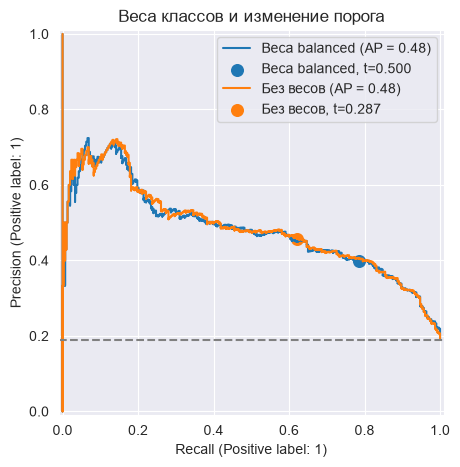

In [18]:
comparison_33 = pd.DataFrame([score_row('Веса balanced, 0.5', model=balanced),
                                  score_row('Без весов, t_F1', model=baseline, threshold=t_F1)])
display(comparison_33)
fig, ax = plt.subplots(figsize=(8, 5))
for name, model, threshold in [('Веса balanced', balanced, 0.5), ('Без весов', baseline, t_F1)]:
    score = model.predict_proba(X_test)[:, 1]
    metrics.PrecisionRecallDisplay.from_predictions(y_test, score, name=name, ax=ax)
    pred = score >= threshold
    ax.scatter(metrics.recall_score(y_test, pred), metrics.precision_score(y_test, pred, zero_division=0),
               s=70, label=f'{name}, t={threshold:.3f}')
ax.axhline(y_test.mean(), ls='--', color='gray')
ax.legend()
plt.title('Веса классов и изменение порога')
plt.show()

PR-кривые близки, AP около 0.4811 у balanced и 0.4848 без весов. Но рабочие точки разные: balanced при 0.5 дает recall около 0.785 и precision 0.399; обычная модель при t_F1 — recall 0.620 и precision 0.457. F1 при этом почти одинаковая, около 0.529 и 0.527.

В этом опыте взвешивание в основном похоже на смягчение порога: ранжирование меняется мало, а отбор становится шире. Однако это не точное равенство. Веса меняют оптимизируемую функцию и могут менять все коэффициенты, а сдвиг порога вообще не переобучает модель. Совпадение PR-кривых не гарантировано.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
all_results = pd.DataFrame([
    score_row('Всегда 0', proba=np.zeros(len(y_test))),
    score_row('Свой GD', model=custom_wine),
    *model_results, *threshold_results.iloc[1:].to_dict('records'),
    score_row('NearMiss → scaler (проверка порядка)', model=nearmiss_before_scaling)])
display(all_results)
# Итоговое правило задаем сценарием: максимальный precision при recall >= 0.7
# на validation. Модель без весов позволяет независимо менять этот компромисс.
print('Выбранный на validation порог t_R:', t_R)
display(threshold_table[threshold_table['Порог'] == t_R])
display(threshold_results[threshold_results['Модель'] == 'Без весов, t_R'])

,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,Всегда 0,0.500000,0.810150,0.000000,0.000000,0.000000,0.500000,0.189850
1,Свой GD,0.500000,0.814536,0.520000,0.300330,0.380753,0.820562,0.483769
2,Без весов,0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
3,Веса balanced,0.500000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
4,RandomUnderSampler,0.500000,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
5,NearMiss-2,0.500000,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
6,RandomOverSampler,0.500000,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
7,SMOTE,0.500000,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
8,"Без весов, t_F1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
9,"Без весов, t_R",0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


Выбранный на validation порог t_R: 0.23635860938278658


,Порог,precision,recall,F1
641,0.236359,0.426117,0.704545,0.531049


,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
2,"Без весов, t_R",0.236359,0.760025,0.42126,0.706271,0.527744,0.820876,0.484766


Для сервиса с ограничением recall >= 0.7 я предлагаю обычную логрегрессию со StandardScaler и порогом t_R около 0.23636. Порог выбран по validation, а не по лучшему результату на test. Балансировка не обязательна: нужный компромисс можно задать порогом, сохранив все исходные обучающие наблюдения.

На отложенных данных у этого варианта precision около 0.421, recall 0.706, F1 0.528 и AP 0.485. Balanced при 0.5 дает более широкий отбор (recall 0.785), но ниже precision (0.399). Для сравнения, порог 0.5 у обычной модели дает precision 0.523, но теряет около 70% хороших вин.

Качество пока скромное: меньше половины рекомендованных вин действительно относятся к классу 1. Если сервису нужна одновременно высокая надежность подборки и широкий охват, одной смены порога недостаточно — понадобятся более информативные признаки или другая модель. Выбор выше фиксирую для демонстрации; тестовые метрики не использую для повторной настройки.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)
final_model = baseline
final_threshold = t_R
joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}, indent=2), encoding='utf-8')
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
print('Сохранено в', app_dir.resolve())
print('Порог:', final_threshold)

Сохранено в C:\Users\amirh\PycharmProjects\ml_hse_2026\homework\hw_3\wine_app
Порог: 0.23635860938278658


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

Приложение: **[открыть в Streamlit Cloud](https://mlhse3-bos2kpnue2j5w7bcw25fuo.streamlit.app/)**.

Публичный GitHub-репозиторий: [arifruette/ml_hse_3_task](https://github.com/arifruette/ml_hse_3_task).

Исходники приложения находятся в папке [wine_app](wine_app/), инструкция запуска — в [README.md](wine_app/README.md). Архив для сдачи: `wine_app.zip` рядом с ноутбуком.

Приложение опубликовано и проверено: оценка одного вина, модельные метрики, пакетное предсказание и коэффициенты модели работают. Метрики и предсказания проверочного CSV совпали с локальными результатами.

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷